<a href="https://colab.research.google.com/github/Fer-Xavier/Imagenes-/blob/main/Examen_practico_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Examen práctico de ML
## Dr. Carlos Villaseñor
### Asignaturas:
### Seminario de Solución de Problemas de Inteligencia Artificial II
### Sistemas Inteligentes IV


Bienvenido a tu examen práctico de la asignatura de Seminario de Solución de problemas de Inteligencia Artificial 2, Te pido que leas atentamente las instrucciones. Tendrás como máximo para terminar este examen. ¡Exito!.


# Reglas del examen



1. Puedes revisar cualquiera de los proyectos anteriores que hemos hecho
2. Puedes buscar información en stackoverflow o páginas similares para revisar errores en tu código
3. Puedes usar la documentación de sklearn
4. Esta prohibido abrir la página de Kaggle.com, el solo hecho de tener está página abierta en el momento del examen provocará la cancelación del examen y por lo tanto 30 puntos menos en su calificación final
5. No se permite hablar ni mandar mensajes, a otros compañeros o externos a la clase durante el examen, al igual que el uso de celular. Esto causara la cancelación inmediata del examen.
6. Se prohibe usar ChatGPT o Copilot o cualquier otra ayuda de generación de texto o NLP. Abrir estás páginas o tener el plugin instalado en su IDE provocará la cancelación inmediata del examen.
7. Para asegurar que el examen sea justo, no se permite ir al baño durante la aplicación del examen (ya que pueden obtener información de otros medios).
8. Antes de proceder al examen tiene que aceptar estas condiciones o si no el examen quedará invalido.




¿Acepta usted estás condiciones?


In [15]:
Acepta = "Si"

##Preparación

Paso 1. Define tus datos de estudiante (Tus datos serán comparados con un script)

In [3]:
# Tu código de estudiante como un número entero
codigo = 223865203

# Nombre completo del estudiante (comenzando por nombre)
nombre = "Fernando Xavier Reyes López"

# Carrera en su acrónimo: INCO, INRI INNI
Carrera = "INRO"


Paso 2. Corre la siguiente función:

In [4]:
def getProblem(codigo_de_estudiante):
    sum = 0
    for digit in str(codigo_de_estudiante):
      sum += int(digit)
    return sum % 7

Paso 3. Obten el número de tu problema

In [5]:
problema = getProblem(codigo)
print('Tu problema a resolver es el número: ', problema)

Tu problema a resolver es el número:  3


Paso 4. En los siguientes comandos modifica la X por el número de problema que te tocó

In [7]:
!wget "https://github.com/Dr-Carlos-Villasenor/MLTest/raw/main/problem3.zip"
!unzip problemX.zip

--2026-11-25 18:35:25--  https://github.com/Dr-Carlos-Villasenor/MLTest/raw/main/problem3.zip
Resolving github.com (github.com)... 20.27.163.208
Connecting to github.com (github.com)|20.27.163.208|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/Dr-Carlos-Villasenor/MLTest/main/problem3.zip [following]
--2026-11-25 18:35:25--  https://raw.githubusercontent.com/Dr-Carlos-Villasenor/MLTest/main/problem3.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 23215 (23K) [application/zip]
Saving to: ‘problem3.zip’

problem3.zip        100%[===================>]  22.67K  --.-KB/s    in 0.007s  

2026-11-25 18:35:26 (3.22 MB/s) - ‘problem3.zip’ saved [23215/23215]

unzip:  cannot find or open problemX.zi

Paso 5. Lee el archivo de texto con las instrucciones

In [16]:
!unzip -o problem3.zip

with open("problem3/Instrucciones.txt") as archivo:
    print(archivo.read())

Archive:  problem3.zip
  inflating: problem3/data.csv       
  inflating: problem3/desktop.ini    
  inflating: problem3/Instrucciones.txt  
Pedido del cliente:
 
Hemos juntado datos del grano de cafe y de cateadores profesionales, nos gustaría usar tus habilidades en ML para descubrir tendencias en los datos. En particular nos importa ver como afecta la altitud y la region al sabor.

¿Sería posible crear una visualización 2D de los datos usando las variables: Aroma, Flavor, Aftertaste, Acidity, Body, Balance, Uniformity, Clean Cup, Sweetness y posteriormente dibujar las que pertenezcan a taiwan y las que no?



Paso 6. Carga los datos

In [17]:
import pandas as pd

df = pd.read_csv('problem3/data.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 207 entries, 0 to 206
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             207 non-null    int64  
 1   ID                     207 non-null    int64  
 2   Country of Origin      207 non-null    object 
 3   Farm Name              205 non-null    object 
 4   Lot Number             206 non-null    object 
 5   Mill                   204 non-null    object 
 6   ICO Number             75 non-null     object 
 7   Company                207 non-null    object 
 8   Altitude               206 non-null    object 
 9   Region                 205 non-null    object 
 10  Producer               206 non-null    object 
 11  Number of Bags         207 non-null    int64  
 12  Bag Weight             207 non-null    object 
 13  In-Country Partner     207 non-null    object 
 14  Harvest Year           207 non-null    object 
 15  Gradin

## Exámen Practico


Paso 7. Usa todo lo que has aprendido en la clase para tratar se satisfacer el pedido del cliente. Recuerda las buenas prácticas en ML. Incluye los cuadros de texto que sean necesarios para entender tu código, imagina que esto es algo que va a ver tu cliente o algun otro ingeniero.

La primera parte es definir las librerias para toda la parte de los arreglos, limpieza, gráfica y el modelo usado. Además de leer los datos, y limpiar los datos antes de procesarlos.

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Leer datos
data = pd.read_csv('problem3/data.csv')

# Limpiar datos
data = data.dropna()

Posteriormente, se definieron en un arreglo las variables solicitadas por el cliente: Aroma, Flavor, Aftertaste, Acidity, Body, Balance, Uniformity, Clean Cup, Sweetness


Después se estandarizaron los datos para que todos tuvieran una escala comparable y no tuviera variaciones. Con esto ya podemos reducir las dimensiones del modelo a 2 dimensiones para la visualización 2D, osea una gráfica.

Finalmente en esta segunda parte se guardo en una variable los datos del país Taiwan para saber si pertenece o no, esto se va a usar a la hora de gráficar.

In [20]:
# Seleccionar las variables
x = np.array(data[['Aroma', 'Flavor', 'Aftertaste','Acidity', 'Body', 'Balance','Uniformity', 'Clean Cup', 'Sweetness']])

# Estandarizar los datos
scaler = StandardScaler()
x = scaler.fit_transform(x)

# Reducir a 2 dimensiones
modelo = PCA(n_components=2)
x_PCA = modelo.fit_transform(x)

# Identificar los datos de Taiwan
taiwan = data['Country of Origin'] == 'Taiwan'

Lo ultimo que nos queda es gráficar en 2D los componentes 1 y 2 de los datos del grano de cafe que pertenecen a taiwan y los que no con el modelo usado x_PCA, se añadieron unas etiquetas para identicar cada eje y en el titulo aparece el modelo PCA y 'Características del cafe'.

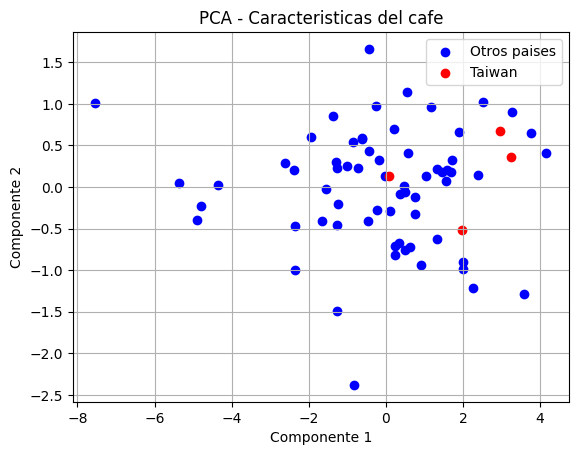

In [21]:
# Graficar datos que no pertenecen a Taiwan
plt.figure()
plt.scatter( x_PCA[~taiwan, 0], x_PCA[~taiwan, 1], color='blue', label='Otros paises')

# Graficar datos pertenecientes a Taiwan
plt.scatter( x_PCA[taiwan, 0], x_PCA[taiwan, 1], color='red', label='Taiwan')

plt.xlabel('Componente 1')
plt.ylabel('Componente 2')
plt.title('PCA - Caracteristicas del cafe')
plt.legend()
plt.grid()
plt.show()

## Fin del examen

¿Qué te parecio el examen?, cualquier sugerencia para mejorar es bienvenida, dejamela en el siguiente bloque.

Respuesta:

Fue muy sencillo de entender, pero me atore un poco en el paso 4.

# Prepara tu examen para subirlo

Paso Final. Asegurate que el notevbook tenga corrido todas las pestañas (solo correré tu código en caso de dudas). Ve a la pesataña de File y luego en Download, descarga el archivo en formato ".ipynb"

Sube el archivo en el espacio correspondiente de Classroom.